**PÓS-GRADUAÇÃO · DATA SCIENCE & BIG DATA APLICADOS NA INDÚSTRIA**

# Aula 05 · Exercício 02
## Agrupamento de máquinas industriais

| Identificação | Dados |
| :--- | :--- |
| **Aluno** | Carlos Alexandre Duarte Pereira |
| **Curso** | Data Science & Big Data Aplicados na Indústria |
| **Disciplina** | Data Science e Big Data |
| **Professor** | Me. Daniel Vieira |
| **Data** | 31/10/2026 |

---

**Tema:** aprendizado não supervisionado com K-Means.

Análise de 12 máquinas a partir da vibração mecânica (mm/s) e da corrente elétrica (A).


In [1]:
# Importação das bibliotecas
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from IPython.display import display

# Imagens com boa resolução, mantendo o tamanho de exibição dos gráficos.
%config InlineBackend.figure_format = 'retina'

In [2]:
# 1. CRIAÇÃO DO DATAFRAME
dados = {
    "maquina": ["M01", "M02", "M03", "M04", "M05", "M06",
                "M07", "M08", "M09", "M10", "M11", "M12"],
    "vibracao": [1.2, 1.5, 1.3, 1.7, 3.5, 3.8, 4.0, 4.2, 7.5, 8.0, 8.5, 9.0],
    "corrente": [5.0, 5.5, 5.2, 6.0, 10.0, 11.0, 10.5, 12.0, 18.0, 19.0, 20.0, 21.0]
}
df = pd.DataFrame(dados)
df.head(12)

,maquina,vibracao,corrente
0,M01,1.2,5.0
1,M02,1.5,5.5
2,M03,1.3,5.2
3,M04,1.7,6.0
4,M05,3.5,10.0
5,M06,3.8,11.0
6,M07,4.0,10.5
7,M08,4.2,12.0
8,M09,7.5,18.0
9,M10,8.0,19.0


In [3]:
# 2. SELEÇÃO DAS VARIÁVEIS
# A identificação da máquina não participa do agrupamento.
variaveis = df[["vibracao", "corrente"]]
variaveis.head(12)

,vibracao,corrente
0,1.2,5.0
1,1.5,5.5
2,1.3,5.2
3,1.7,6.0
4,3.5,10.0
5,3.8,11.0
6,4.0,10.5
7,4.2,12.0
8,7.5,18.0
9,8.0,19.0


In [4]:
# 3. PADRONIZAÇÃO DOS DADOS
# Evita que a diferença de escala entre as variáveis domine as distâncias.
scaler = StandardScaler()
X = scaler.fit_transform(variaveis)
display(pd.DataFrame(X, columns=["vibracao_padronizada", "corrente_padronizada"],
                     index=df["maquina"]).round(4))

,vibracao_padronizada,corrente_padronizada
maquina,,
M01,-1.1648,-1.1852
M02,-1.0594,-1.0997
M03,-1.1297,-1.1510
M04,-0.9892,-1.0142
M05,-0.3570,-0.3305
M06,-0.2517,-0.1595
M07,-0.1814,-0.2450
M08,-0.1112,0.0114
M09,1.0477,1.0370


In [5]:
# 4. CRIAÇÃO E TREINAMENTO DO K-MEANS COM K = 3
modelo = KMeans(n_clusters=3, random_state=42, n_init=10)
modelo.fit(X);

In [6]:
# 5. IDENTIFICAÇÃO DOS GRUPOS NO DATAFRAME
df["grupo"] = modelo.labels_
# Os números dos grupos são identificadores, sem ordem de gravidade.
display(df.sort_values(["grupo", "vibracao"]))

resumo = df.groupby("grupo").agg(
    maquinas=("maquina", lambda valores: ", ".join(valores)),
    quantidade=("maquina", "count"),
    vibracao_media_mm_s=("vibracao", "mean"),
    corrente_media_a=("corrente", "mean")
)
print("Resumo por grupo:")
display(resumo.round(3))

,maquina,vibracao,corrente,grupo
4,M05,3.5,10.0,0
5,M06,3.8,11.0,0
6,M07,4.0,10.5,0
7,M08,4.2,12.0,0
8,M09,7.5,18.0,1
9,M10,8.0,19.0,1
10,M11,8.5,20.0,1
11,M12,9.0,21.0,1
0,M01,1.2,5.0,2
2,M03,1.3,5.2,2


Resumo por grupo:


,maquinas,quantidade,vibracao_media_mm_s,corrente_media_a
grupo,,,,
0,"M05, M06, M07, M08",4,3.875,10.875
1,"M09, M10, M11, M12",4,8.250,19.500
2,"M01, M02, M03, M04",4,1.425,5.425


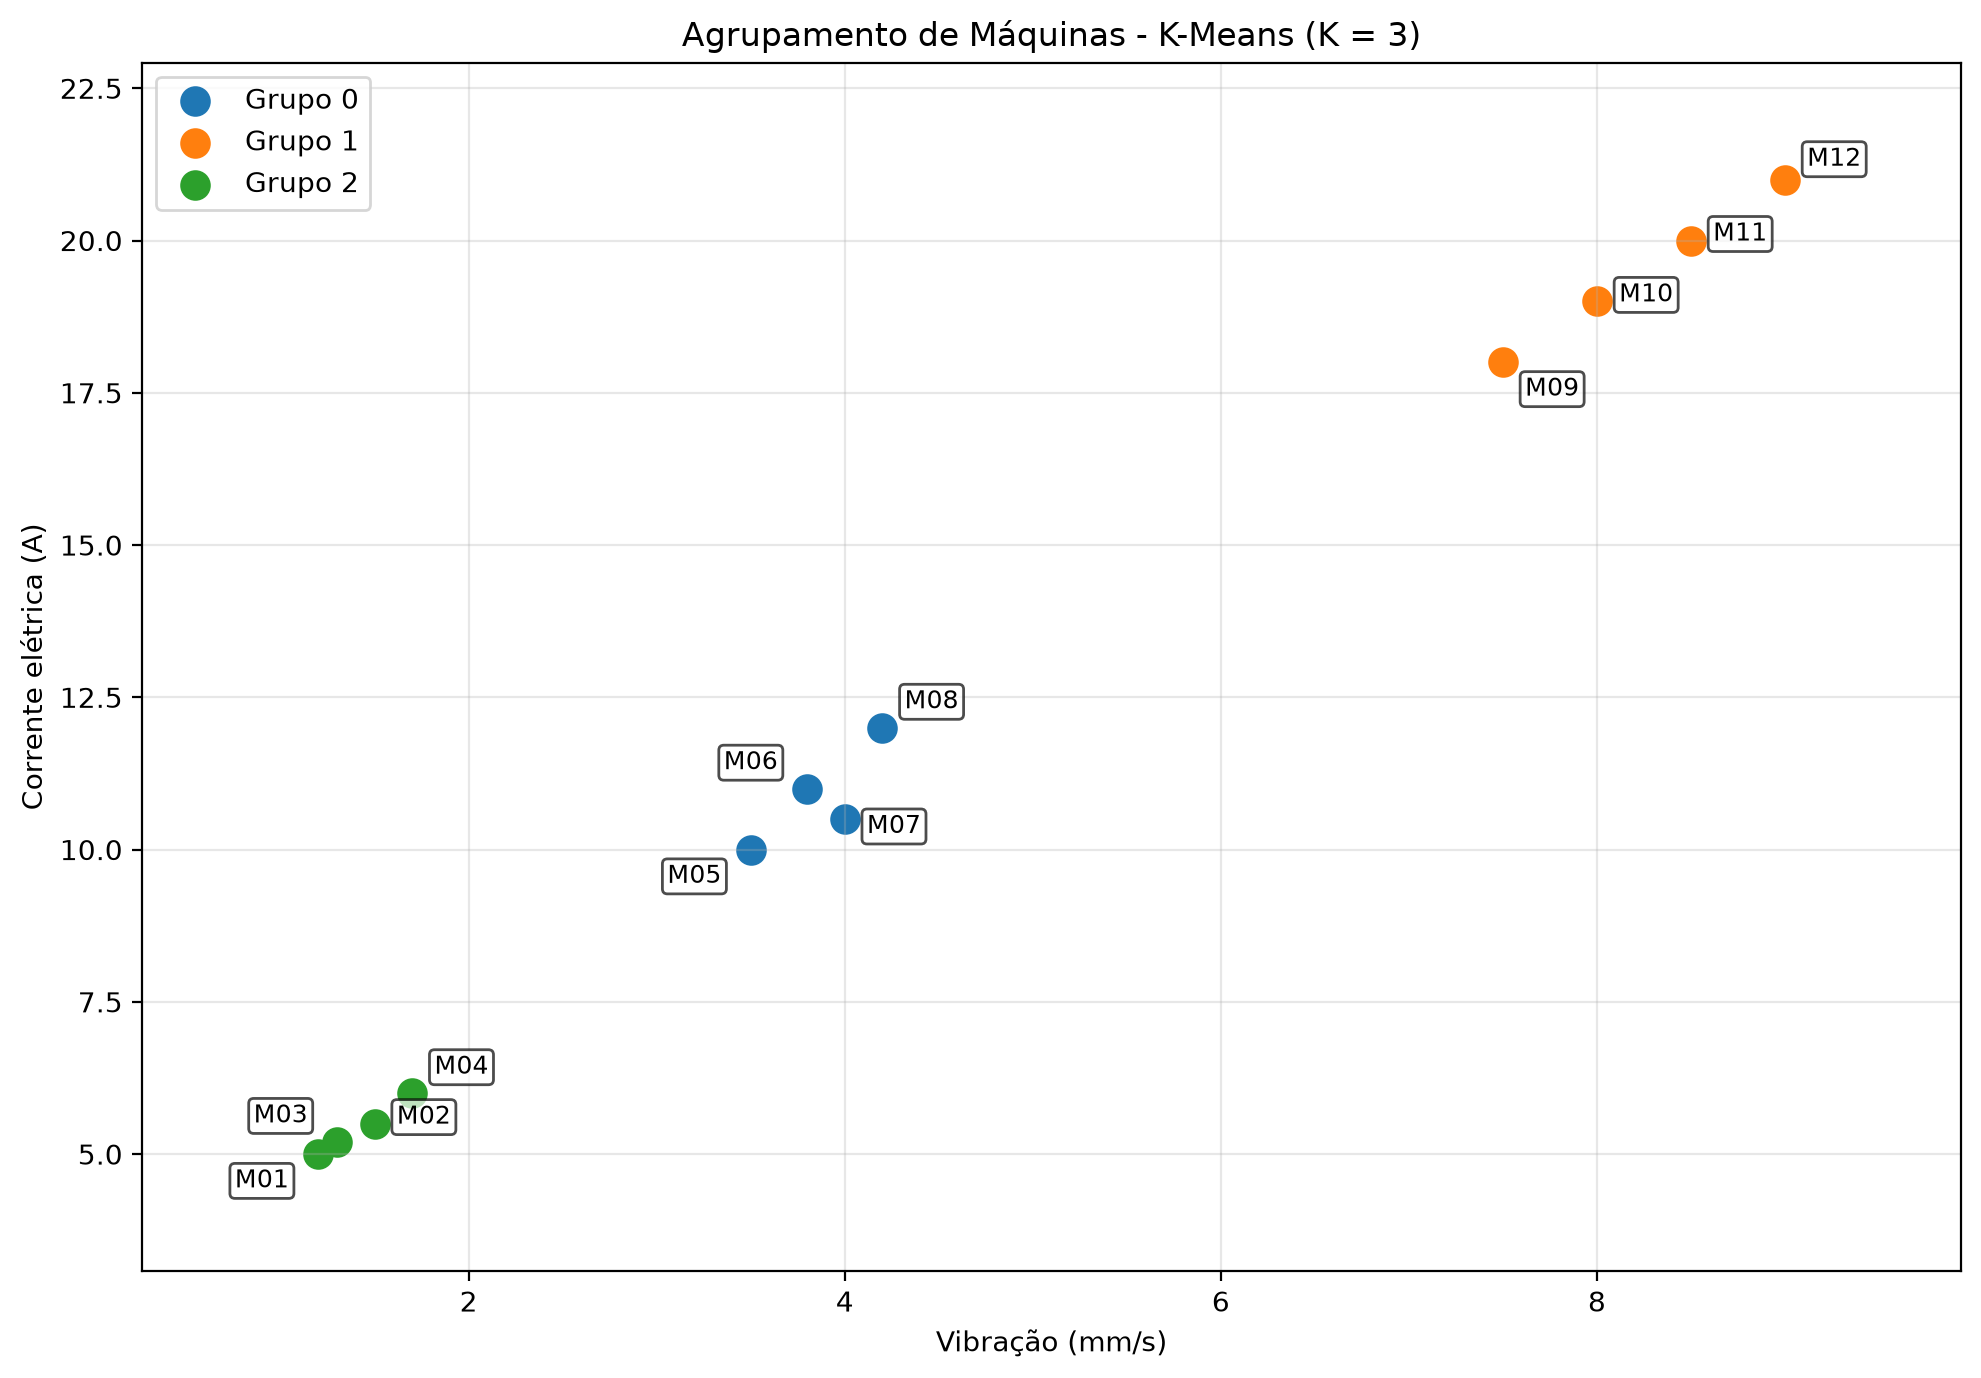

In [7]:
# 6. GRÁFICO DE DISPERSÃO DOS AGRUPAMENTOS
plt.figure(figsize=(10, 7))
for grupo, dados_grupo in df.groupby("grupo"):
    plt.scatter(dados_grupo["vibracao"], dados_grupo["corrente"],
                s=100, label=f"Grupo {grupo}")

deslocamentos = {
    "M01": (-30, -12), "M02": (8, 0), "M03": (-30, 7), "M04": (8, 7),
    "M05": (-30, -12), "M06": (-30, 7), "M07": (8, -5), "M08": (8, 7),
    "M09": (8, -12), "M10": (8, 0), "M11": (8, 0), "M12": (8, 5)
}
for _, linha in df.iterrows():
    plt.annotate(linha["maquina"], (linha["vibracao"], linha["corrente"]),
                 xytext=deslocamentos[linha["maquina"]], textcoords="offset points",
                 fontsize=9,
                 bbox=dict(boxstyle="round,pad=0.2", fc="white", alpha=0.7))
plt.xlabel("Vibração (mm/s)")
plt.ylabel("Corrente elétrica (A)")
plt.title("Agrupamento de Máquinas - K-Means (K = 3)")
plt.legend()
plt.margins(x=0.12, y=0.12)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

,K,inercia_WCSS
0,1,24.0000
1,2,3.6483
2,3,0.4319
3,4,0.1917
4,5,0.1251
5,6,0.0950
6,7,0.0650
7,8,0.0376


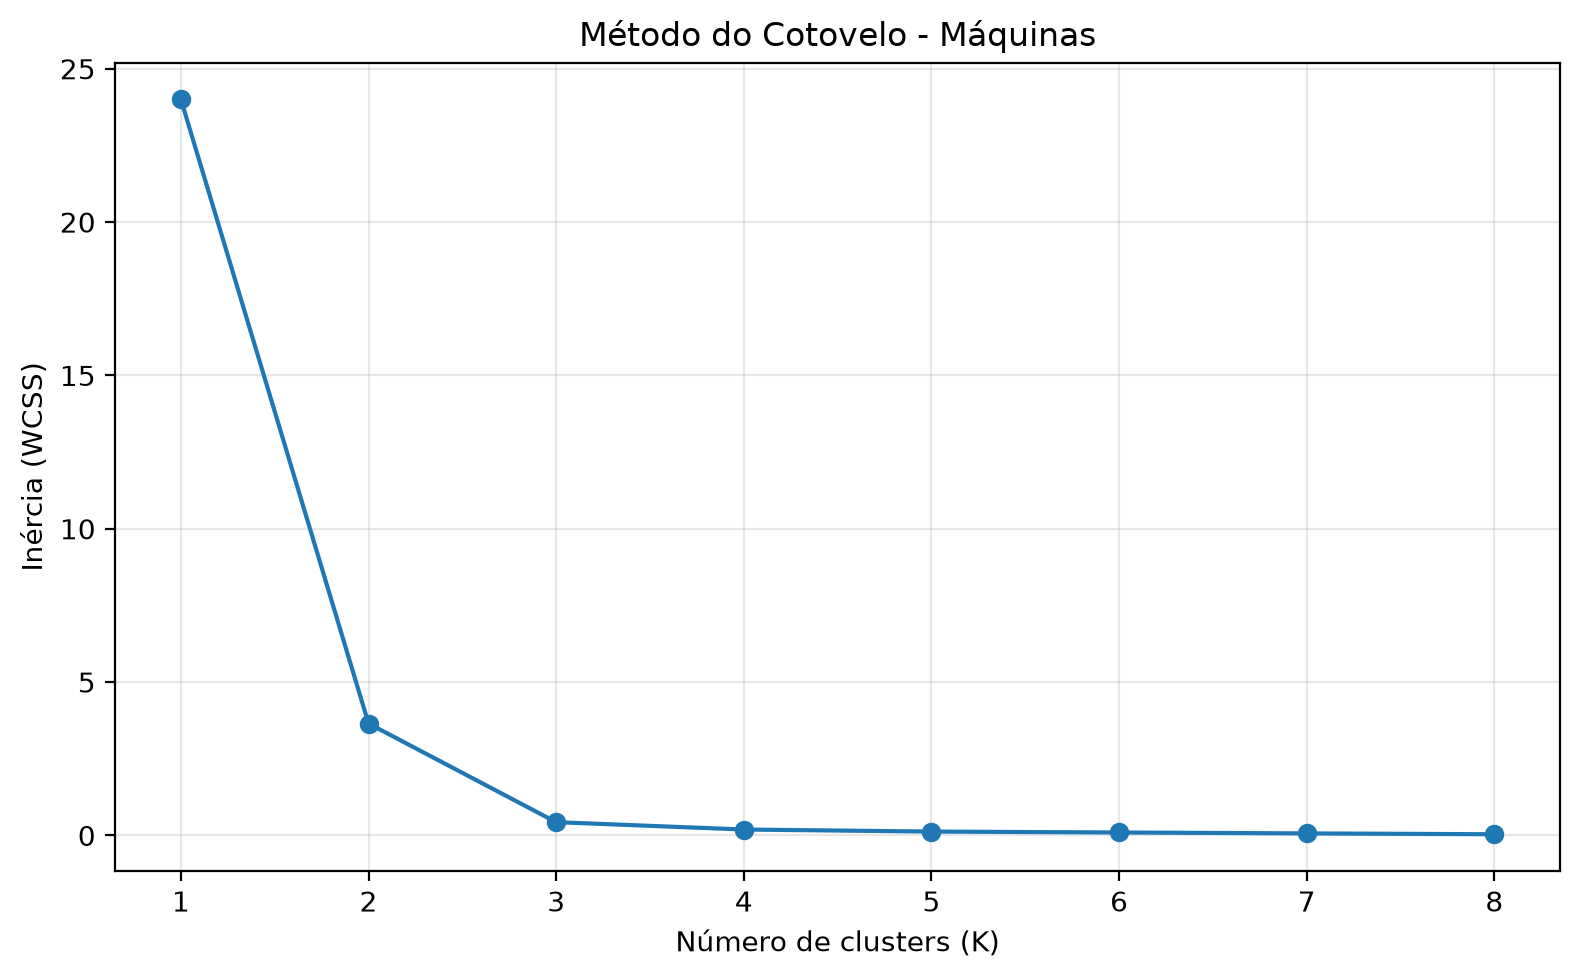

Redução da inércia de K=2 para K=3: 88.16%


In [8]:
# 7. MÉTODO DO COTOVELO
inercias = []
valores_k = range(1, 9)
for k in valores_k:
    modelo_k = KMeans(n_clusters=k, random_state=42, n_init=10)
    modelo_k.fit(X)
    inercias.append(modelo_k.inertia_)

display(pd.DataFrame({"K": list(valores_k), "inercia_WCSS": inercias}).round(4))
plt.figure(figsize=(8, 5))
plt.plot(valores_k, inercias, marker="o")
plt.xlabel("Número de clusters (K)")
plt.ylabel("Inércia (WCSS)")
plt.title("Método do Cotovelo - Máquinas")
plt.xticks(valores_k)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()
print(f"Redução da inércia de K=2 para K=3: {(inercias[1] - inercias[2]) / inercias[1] * 100:.2f}%")

## Questões para análise

**a) Quantos grupos de máquinas foram identificados?**

Foram identificados 3 grupos, conforme o valor K = 3 definido no modelo.

**b) Quais máquinas apresentam os menores valores de vibração e corrente elétrica?**

M01, M02, M03 e M04 formam o grupo com os menores valores: vibração entre 1,2 e 1,7 mm/s e corrente entre 5,0 e 6,0 A. Nesse conjunto, M01 apresenta os menores valores individuais das duas variáveis: 1,2 mm/s e 5,0 A.

**c) Qual grupo apresenta os maiores valores dessas variáveis?**

O grupo 1, formado por M09, M10, M11 e M12. A vibração varia de 7,5 a 9,0 mm/s e a corrente varia de 18,0 a 21,0 A. As médias são 8,25 mm/s e 19,5 A. Os números dos grupos são apenas identificadores e podem mudar com outra configuração ou versão do algoritmo.

**d) Os agrupamentos podem ajudar a equipe de manutenção a identificar máquinas que precisam de inspeção? Explique.**

Sim. Os grupos permitem comparar máquinas de comportamento semelhante e destacar aquelas com vibração e corrente mais elevadas para investigação. A equipe pode usar essa informação para priorizar inspeções, verificando também o histórico, a carga e as condições de operação de cada máquina. O agrupamento, sozinho, não determina a necessidade de intervenção.

**e) Uma máquina com vibração e corrente elevadas necessariamente apresenta uma falha? Justifique.**

Não. Esses valores também podem estar relacionados à carga de trabalho, à velocidade, às características do equipamento ou às condições de medição. Para avaliar uma possível falha, é necessário comparar os valores com o histórico e os limites aplicáveis à máquina e realizar uma inspeção. O K-Means identifica semelhanças entre os dados; ele não diagnostica falhas.

**f) O método do cotovelo confirma K = 3 como uma escolha adequada?**

A curva sustenta K = 3 como uma escolha adequada: a inércia cai de aproximadamente 3,6483 em K = 2 para 0,4319 em K = 3, uma redução de 88,16%. Ao passar para K = 4, a redução absoluta é bem menor, chegando a 0,1917. Isso é coerente com os três perfis observados no gráfico de dispersão. O cotovelo é um critério visual de apoio e não comprova uma quantidade única de grupos.
